# 1. Exploración de los datos

Este notebook muestra los datos de demo de Robyn antes de entrenar el modelo. Los datos son simulados. No son de una empresa real.

In [1]:
from mmm import plots
from mmm.data import CHANNELS, load_raw, prepare_features

df = load_raw()
df.shape

(208, 12)

El dataset tiene 208 semanas. Cada fila es una semana con las ventas, la inversión en 5 canales pagos y algunos controles.

In [2]:
df[["revenue", *CHANNELS]].describe().round(0)

,revenue,tv_S,ooh_S,print_S,facebook_S,search_S
count,208.0,208.0,208.0,208.0,208.0,208.0
mean,1822143.0,14844.0,43218.0,3729.0,2146.0,5916.0
std,716229.0,28558.0,83991.0,6483.0,3160.0,4703.0
min,672250.0,0.0,0.0,0.0,0.0,0.0
25%,1165211.0,0.0,0.0,0.0,0.0,2353.0
50%,1874514.0,0.0,0.0,0.0,0.0,4807.0
75%,2378407.0,18407.0,50858.0,4768.0,3623.0,8537.0
max,3827520.0,158047.0,500362.0,31922.0,15400.0,17880.0


## Ventas

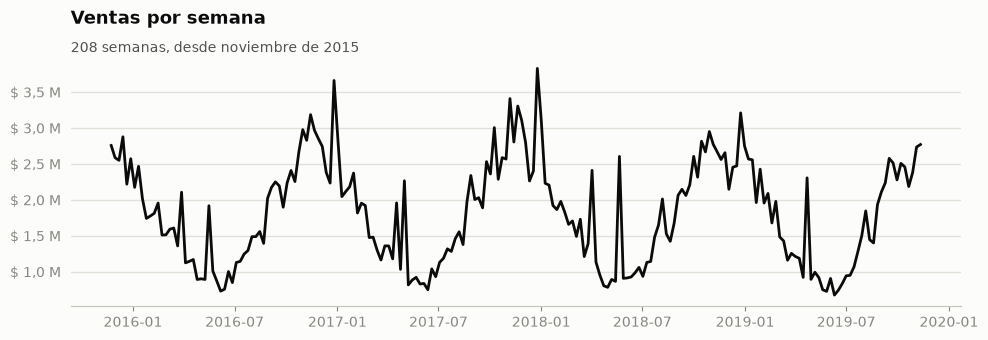

In [3]:
plots.plot_revenue(df);

## Inversión por canal

La inversión llega en picos. Vía pública tiene pocas semanas con inversión, pero muy grandes.

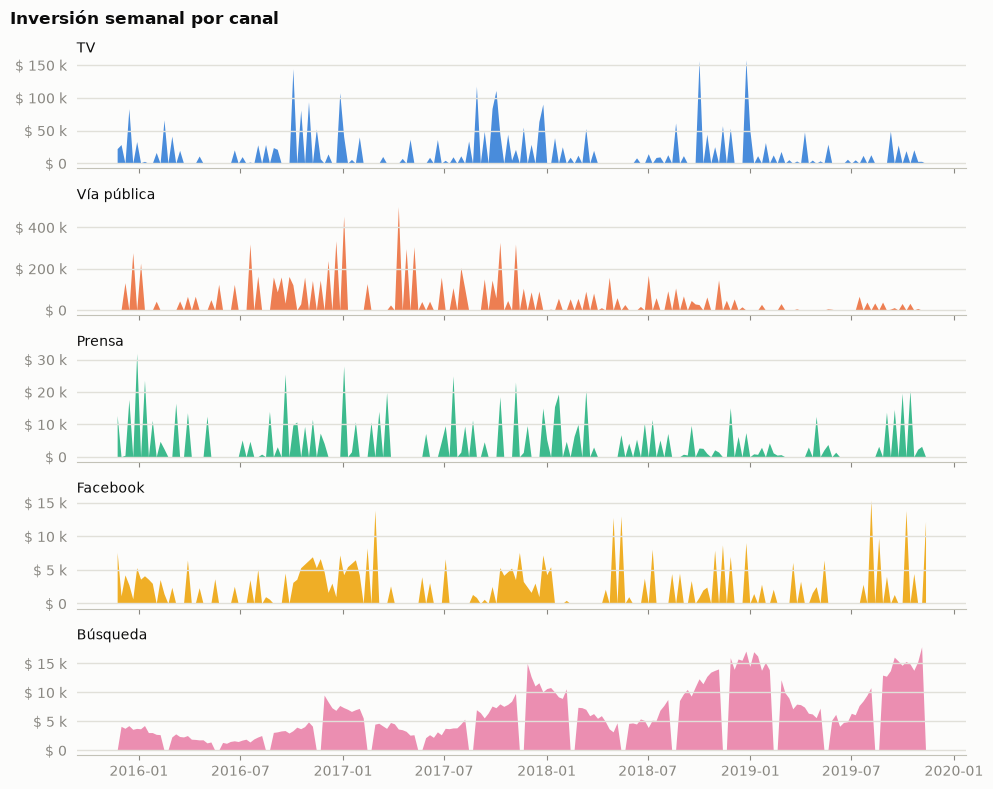

In [4]:
plots.plot_spend(df);

## Correlación con las ventas

Una correlación alta no prueba que el canal cause ventas. El modelo separa el efecto de cada canal del de los controles.

In [5]:
df[["revenue", *CHANNELS, "newsletter", "competitor_sales_B"]].corr()["revenue"].round(2)

revenue               1.00
tv_S                  0.42
ooh_S                 0.10
print_S               0.23
facebook_S            0.32
search_S              0.44
newsletter            0.41
competitor_sales_B    0.92
Name: revenue, dtype: float64

## Controles que agrega la preparación

`prepare_features` agrega una marca de feriado de Alemania, una tendencia de 0 a 1 y una columna por evento. También escala la newsletter y las ventas de la competencia a un máximo de 1.

In [6]:
prepared, controls = prepare_features(df)
controls

['newsletter',
 'competitor_sales_B',
 'holiday',
 'trend',
 'event_event1',
 'event_event2']